In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import easygdf
import pysdds
from opal import get_screen_from_h5

In [6]:
gpt_data_path = '../data/gpt/saved_runs/1nc'
opal_data_path = '../data/opal/saved_runs/1nc_yag4'

In [7]:
# load gpt stats
gpt_stats_blocks = easygdf.load(os.path.join(gpt_data_path, 'stats.gdf'))
gpt_stats = {}
for block in gpt_stats_blocks['blocks']:
    gpt_stats[block['name']] = block['value']

In [9]:
# load opal stats
opal_sdds = pysdds.read(os.path.join(opal_data_path, 'input.sdds'))
opal_stats = opal_sdds.columns_to_df()

/nfs/user/jg2347/pysdds/pysdds/readers/readers.py:2623: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_table(buf, encoding="ascii", **opts)


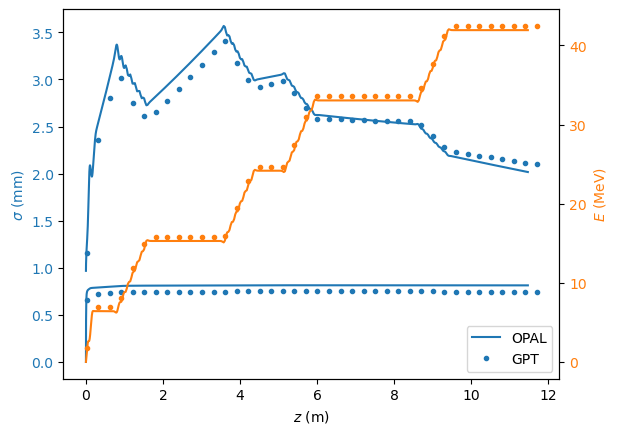

In [44]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
fig, ax = plt.subplots()
ax.plot(opal_stats['ref_z'], 1e3*opal_stats['rms_x'], '-', color=colors[0], label='OPAL')
ax.plot(gpt_stats['avgz'], 1e3*gpt_stats['stdx'], '.', color=colors[0], label='GPT')
ax.plot(opal_stats['ref_z'], 1e3*opal_stats['rms_s'], '-', color=colors[0])
ax.plot(gpt_stats['avgz'], 1e3*gpt_stats['stdz'], '.', color=colors[0])
ax2 = ax.twinx()
ax2.plot(opal_stats['ref_z'], opal_stats['energy'], '-', color=colors[1])
ax2.plot(gpt_stats['avgz'], gpt_stats['avgG']*0.5109989461, '.', color=colors[1])
ax.legend(loc='lower right')
ax.set_xlabel('$z$ (m)')
ax.set_ylabel('$\sigma$ (mm)', color=colors[0])
ax.tick_params(axis='y', labelcolor=colors[0])
ax2.set_ylabel('$E$ (MeV)', color=colors[1])
ax2.tick_params(axis='y', labelcolor=colors[1])